In [1]:
from pathlib import Path
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

ROOT = Path(
    r"D:\Projects\CAPSTONE\QIP\PROJECT_QUANTUM_V3_SUBMISSION"
)

REPORTS = ROOT / "outputs" / "reports"
QUANTUM = REPORTS / "quantum"

OUT = ROOT / "outputs" / "final_comparison_complete"
OUT.mkdir(parents=True, exist_ok=True)

assert ROOT.exists()
assert REPORTS.exists()

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

def load_csv(name):
    path = REPORTS / name
    if not path.exists():
        print("Missing:", name)
        return None
    return pd.read_csv(path, low_memory=False)

def load_json(path):
    if not path.exists():
        print("Missing:", path)
        return None
    with open(path, encoding="utf-8-sig") as f:
        return json.load(f)

def find_column(df, aliases):
    lookup = {str(c).lower(): c for c in df.columns}
    for alias in aliases:
        if alias.lower() in lookup:
            return lookup[alias.lower()]
    return None

print("PROJECT QUANTUM V3.4")
print("Reports:", REPORTS)
print("Output:", OUT)

PROJECT QUANTUM V3.4
Reports: D:\Projects\CAPSTONE\QIP\PROJECT_QUANTUM_V3_SUBMISSION\outputs\reports
Output: D:\Projects\CAPSTONE\QIP\PROJECT_QUANTUM_V3_SUBMISSION\outputs\final_comparison_complete


In [2]:
rf_summaries = {}

for resolution in [16, 32, 240]:

    name = f"msd_test_calibrated_summary_{resolution}.csv"

    rf_summaries[resolution] = load_csv(name)

    if rf_summaries[resolution] is not None:
        print(f"\nRF {resolution}×{resolution}")
        display(rf_summaries[resolution])

METRICS = {
    "Macro Dice": ["macro_dice_mean"],
    "Macro IoU": ["macro_iou_mean"],
    "Active Macro Dice": [
        "macro_dice_present_gt_mean",
        "macro_dice_active_mean"
    ],
    "Active Macro IoU": [
        "macro_iou_present_gt_mean",
        "macro_iou_active_mean"
    ],
    "WT Dice": ["wt_dice_mean", "wt_dice"],
    "TC Dice": ["tc_dice_mean", "tc_dice"],
    "ET Dice": ["et_dice_mean", "et_dice"],
    "Inference Seconds": ["inference_seconds_mean"]
}

rf_records = []

for resolution, df in rf_summaries.items():

    if df is None:
        continue

    method_col = find_column(
        df, ["method", "model", "model_name", "algorithm"]
    )

    if method_col:
        method = df[method_col].astype(str).str.lower()
        matched = df[
            method.str.contains(
                r"random\s*forest|randomforest|\brf\b",
                regex=True
            )
        ]

        if not matched.empty:
            df = matched

    row = {
        "Model": "Random Forest",
        "Resolution": f"{resolution}×{resolution}",
        "Resolution_px": resolution
    }

    for metric, aliases in METRICS.items():

        col = find_column(df, aliases)

        if col:
            values = pd.to_numeric(
                df[col], errors="coerce"
            ).dropna()

            row[metric] = values.mean() if len(values) else np.nan
        else:
            row[metric] = np.nan

    rf_records.append(row)

rf_results = pd.DataFrame(rf_records)

display(rf_results)

rf_results.to_csv(
    OUT / "rf_resolution_comparison.csv",
    index=False
)


RF 16×16


,method,resolution,inference_seconds_mean,inference_seconds_std,macro_dice_mean,macro_dice_std,macro_iou_mean,macro_iou_std,macro_dice_present_gt_mean,macro_dice_present_gt_std,...,ET_fp_mean,ET_fp_std,ET_fn_mean,ET_fn_std,ET_tn_mean,ET_tn_std,ET_empty_prediction_mean,ET_empty_prediction_std,ET_empty_ground_truth_mean,ET_empty_ground_truth_std
0,KMeans,16,0.000976,0.000975,0.198966,0.139767,0.134654,0.112016,0.228618,0.142751,...,13.054054,13.065776,0.807432,1.580361,241.006757,13.422711,0.099662,0.299802,0.535473,0.499162
1,Otsu,16,0.000907,0.000770,0.217234,0.194223,0.147057,0.148804,0.281509,0.197878,...,6.731419,3.231166,0.905405,1.718173,247.329392,3.006133,0.000000,0.000000,0.535473,0.499162
2,RandomForest,16,0.039179,0.015847,0.594388,0.259988,0.529883,0.259947,0.443053,0.327726,...,0.841216,1.856563,0.896959,1.688377,253.219595,3.490246,0.505068,0.500397,0.535473,0.499162
3,Watershed,16,0.002392,0.001563,0.191628,0.150816,0.130812,0.118403,0.212730,0.147070,...,15.420608,22.470747,0.702703,1.549890,238.640203,22.839037,0.099662,0.299802,0.535473,0.499162



RF 32×32


,method,resolution,inference_seconds_mean,inference_seconds_std,macro_dice_mean,macro_dice_std,macro_iou_mean,macro_iou_std,macro_dice_present_gt_mean,macro_dice_present_gt_std,...,ET_fp_mean,ET_fp_std,ET_fn_mean,ET_fn_std,ET_tn_mean,ET_tn_std,ET_empty_prediction_mean,ET_empty_prediction_std,ET_empty_ground_truth_mean,ET_empty_ground_truth_std
0,KMeans,32,0.001081,0.000456,0.115049,0.085486,0.068448,0.053934,0.147880,0.103328,...,75.315878,64.694047,5.798986,8.385294,942.462838,67.362333,0.000000,0.000000,0.461149,0.49891
1,Otsu,32,0.000935,0.000440,0.227763,0.226958,0.158748,0.180016,0.265660,0.225479,...,24.096284,13.606477,2.332770,4.777883,993.682432,11.995085,0.000000,0.000000,0.461149,0.49891
2,RandomForest,32,0.046294,0.018206,0.590548,0.265290,0.513179,0.257086,0.487494,0.327530,...,2.459459,4.719013,2.221284,4.009720,1015.319257,10.115296,0.339527,0.473949,0.461149,0.49891
3,Watershed,32,0.001925,0.000797,0.114611,0.094944,0.069469,0.062500,0.144257,0.108040,...,64.106419,95.099060,5.844595,8.422605,953.672297,97.541196,0.000000,0.000000,0.461149,0.49891



RF 240×240


,method,resolution,inference_seconds_mean,inference_seconds_std,macro_dice_mean,macro_dice_std,macro_iou_mean,macro_iou_std,macro_dice_present_gt_mean,macro_dice_present_gt_std,...,ET_fp_mean,ET_fp_std,ET_fn_mean,ET_fn_std,ET_tn_mean,ET_tn_std,ET_empty_prediction_mean,ET_empty_prediction_std,ET_empty_ground_truth_mean,ET_empty_ground_truth_std
0,KMeans,240,0.017801,0.005215,0.061386,0.050403,0.035149,0.030215,0.071847,0.060262,...,6861.452703,3982.912692,271.939189,383.938037,50454.123311,4069.184284,0.00000,0.000000,0.385135,0.487039
1,Otsu,240,0.001059,0.000187,0.254304,0.262592,0.186984,0.214132,0.274577,0.267188,...,1043.452703,764.483908,108.959459,237.766322,56272.123311,682.072759,0.00000,0.000000,0.385135,0.487039
2,RandomForest,240,0.099080,0.007901,0.476972,0.305772,0.389014,0.271537,0.476246,0.315744,...,140.032095,209.173324,72.180743,130.726602,57175.543919,440.329143,0.10473,0.306464,0.385135,0.487039
3,Watershed,240,0.025794,0.007043,0.061285,0.050954,0.035101,0.030610,0.071748,0.061059,...,7230.668919,4283.650376,272.675676,384.421735,50084.907095,4365.039482,0.00000,0.000000,0.385135,0.487039


,Model,Resolution,Resolution_px,Macro Dice,Macro IoU,Active Macro Dice,Active Macro IoU,WT Dice,TC Dice,ET Dice,Inference Seconds
0,Random Forest,16×16,16,0.594388,0.529883,0.443053,0.357462,0.519943,0.613884,0.649337,0.039179
1,Random Forest,32×32,32,0.590548,0.513179,0.487494,0.393238,0.546760,0.598355,0.626528,0.046294
2,Random Forest,240×240,240,0.476972,0.389014,0.476246,0.376282,0.535234,0.440323,0.455358,0.099080


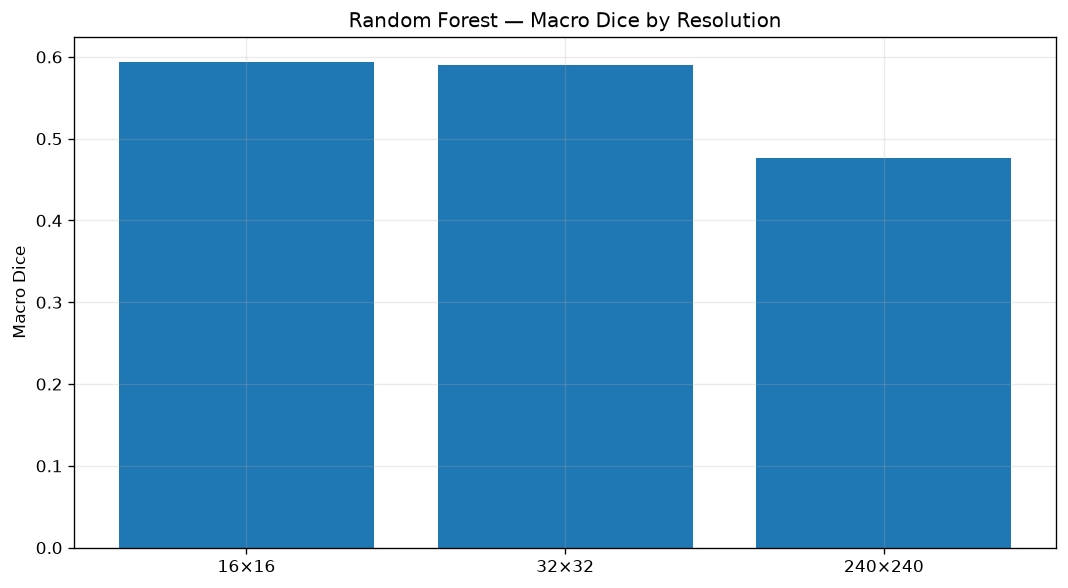

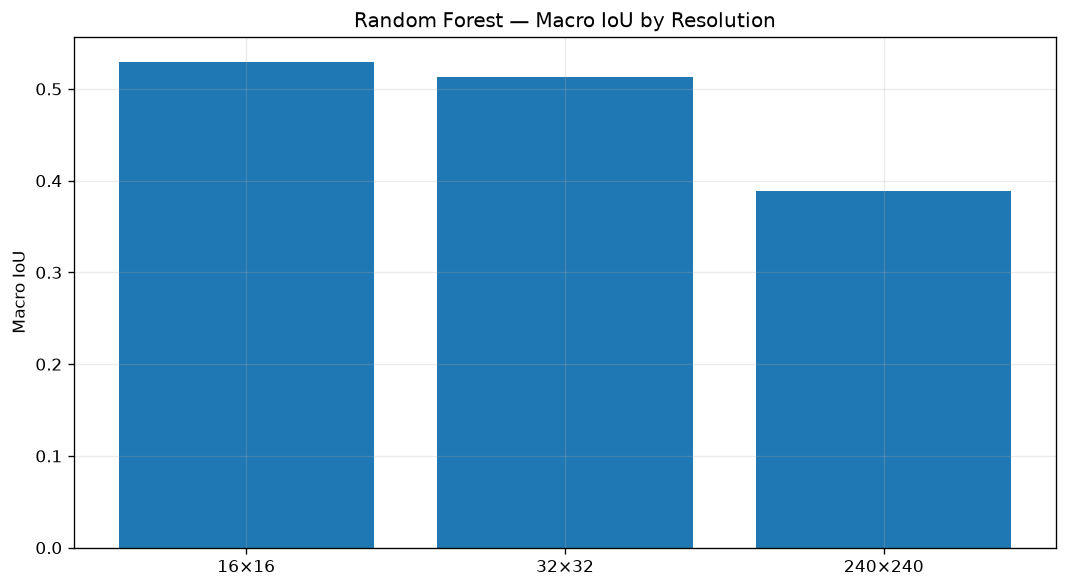

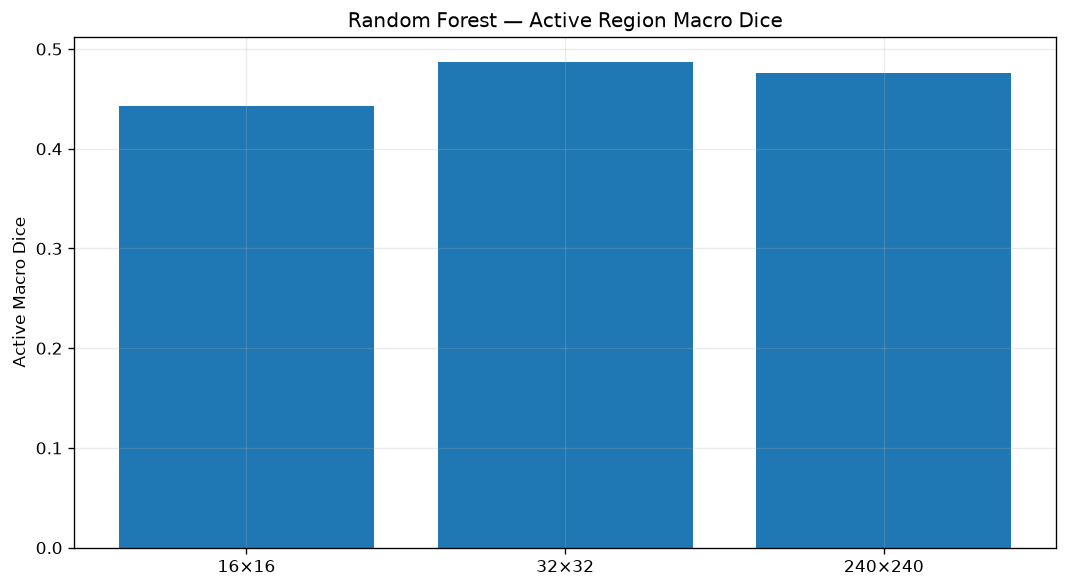

In [3]:
def plot_metric(df, x, y, title, ylabel, filename):

    data = df.dropna(subset=[y]).copy()

    if data.empty:
        print("No values available for:", title)
        return

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.bar(data[x].astype(str), data[y])

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.set_ylim(bottom=0)

    plt.tight_layout()

    plt.savefig(
        OUT / filename,
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()


plot_metric(
    rf_results,
    "Resolution",
    "Macro Dice",
    "Random Forest — Macro Dice by Resolution",
    "Macro Dice",
    "01_RF_Macro_Dice.png"
)

plot_metric(
    rf_results,
    "Resolution",
    "Macro IoU",
    "Random Forest — Macro IoU by Resolution",
    "Macro IoU",
    "02_RF_Macro_IoU.png"
)

plot_metric(
    rf_results,
    "Resolution",
    "Active Macro Dice",
    "Random Forest — Active Region Macro Dice",
    "Active Macro Dice",
    "03_RF_Active_Dice.png"
)

In [4]:
unet_history = load_csv("msd_unet_training_history.csv")
unet_test = load_csv("msd_unet_test_summary.csv")
unet_patient = load_csv("msd_unet_test_per_patient.csv")
unet_slice = load_csv("msd_unet_test_per_slice.csv")
unet_validation = load_csv("msd_unet_validation_summary.csv")

for name, df in [
    ("Training history", unet_history),
    ("Held-out test summary", unet_test),
    ("Held-out patient results", unet_patient),
    ("Held-out slice results", unet_slice),
    ("Validation summary", unet_validation)
]:

    print("\n", name)

    if df is not None:
        print("Shape:", df.shape)
        print("Columns:", list(df.columns))
        display(df.head())


 Training history
Shape: (10, 5)
Columns: ['epoch', 'train_loss', 'validation_active_macro_dice', 'learning_rate', 'epoch_seconds']


,epoch,train_loss,validation_active_macro_dice,learning_rate,epoch_seconds
0,1,0.366803,0.641340,0.001,15.094420
1,2,0.276189,0.660151,0.001,14.305822
2,3,0.251410,0.701295,0.001,14.134161
3,4,0.237926,0.705184,0.001,14.146667
4,5,0.227567,0.713919,0.001,14.487374



 Held-out test summary
Shape: (1, 82)
Columns: ['method', 'resolution', 'macro_dice_mean', 'macro_dice_std', 'macro_iou_mean', 'macro_iou_std', 'macro_dice_present_gt_mean', 'macro_dice_present_gt_std', 'macro_iou_present_gt_mean', 'macro_iou_present_gt_std', 'macro_dice_active_mean', 'macro_dice_active_std', 'macro_iou_active_mean', 'macro_iou_active_std', 'n_regions_present_gt_mean', 'n_regions_present_gt_std', 'n_regions_empty_gt_mean', 'n_regions_empty_gt_std', 'n_regions_empty_prediction_mean', 'n_regions_empty_prediction_std', 'n_regions_both_empty_mean', 'n_regions_both_empty_std', 'WT_dice_mean', 'WT_dice_std', 'WT_iou_mean', 'WT_iou_std', 'WT_precision_mean', 'WT_precision_std', 'WT_recall_mean', 'WT_recall_std', 'WT_specificity_mean', 'WT_specificity_std', 'WT_hd95_pixels_mean', 'WT_hd95_pixels_std', 'WT_tp_mean', 'WT_tp_std', 'WT_fp_mean', 'WT_fp_std', 'WT_fn_mean', 'WT_fn_std', 'WT_tn_mean', 'WT_tn_std', 'TC_dice_mean', 'TC_dice_std', 'TC_iou_mean', 'TC_iou_std', 'TC_preci

,method,resolution,macro_dice_mean,macro_dice_std,macro_iou_mean,macro_iou_std,macro_dice_present_gt_mean,macro_dice_present_gt_std,macro_iou_present_gt_mean,macro_iou_present_gt_std,...,ET_hd95_pixels_mean,ET_hd95_pixels_std,ET_tp_mean,ET_tp_std,ET_fp_mean,ET_fp_std,ET_fn_mean,ET_fn_std,ET_tn_mean,ET_tn_std
0,UNet2D,240,0.743423,0.230548,0.66004,0.226139,0.742637,0.223184,0.653937,0.219644,...,9.0956,17.067057,315.675676,347.321005,69.472973,107.807932,57.445946,85.899743,57157.405405,413.430412



 Held-out patient results
Shape: (74, 42)
Columns: ['patient_id', 'method', 'macro_dice', 'macro_iou', 'macro_dice_present_gt', 'macro_iou_present_gt', 'macro_dice_active', 'macro_iou_active', 'n_regions_present_gt', 'n_regions_empty_gt', 'n_regions_empty_prediction', 'n_regions_both_empty', 'WT_dice', 'WT_iou', 'WT_precision', 'WT_recall', 'WT_specificity', 'WT_hd95_pixels', 'WT_tp', 'WT_fp', 'WT_fn', 'WT_tn', 'TC_dice', 'TC_iou', 'TC_precision', 'TC_recall', 'TC_specificity', 'TC_hd95_pixels', 'TC_tp', 'TC_fp', 'TC_fn', 'TC_tn', 'ET_dice', 'ET_iou', 'ET_precision', 'ET_recall', 'ET_specificity', 'ET_hd95_pixels', 'ET_tp', 'ET_fp', 'ET_fn', 'ET_tn']


,patient_id,method,macro_dice,macro_iou,macro_dice_present_gt,macro_iou_present_gt,macro_dice_active,macro_iou_active,n_regions_present_gt,n_regions_empty_gt,...,ET_dice,ET_iou,ET_precision,ET_recall,ET_specificity,ET_hd95_pixels,ET_tp,ET_fp,ET_fn,ET_tn
0,BRATS_002,UNet2D,0.784189,0.653971,0.784189,0.653971,0.784189,0.653971,3.0,0.0,...,0.769750,0.630588,0.970076,0.641973,0.999965,4.181841,77.0,2.0,38.5,57482.5
1,BRATS_007,UNet2D,0.906814,0.831271,0.906814,0.831271,0.906814,0.831271,3.0,0.0,...,0.878859,0.785570,0.840978,0.921649,0.997686,2.636548,739.0,131.5,61.0,56668.5
2,BRATS_015,UNet2D,0.936262,0.880521,0.936262,0.880521,0.936262,0.880521,3.0,0.0,...,0.954335,0.912667,0.962037,0.946755,0.998891,2.118034,1560.5,62.0,88.0,55889.5
3,BRATS_016,UNet2D,0.588736,0.531652,0.588736,0.531652,0.588736,0.531652,3.0,0.0,...,0.384984,0.312987,0.462572,0.329685,0.999414,15.755593,241.0,33.5,132.5,57193.0
4,BRATS_017,UNet2D,0.872788,0.778099,0.872788,0.778099,0.872788,0.778099,3.0,0.0,...,0.850748,0.741557,0.968447,0.763286,0.999666,4.865220,469.5,19.0,138.0,56973.5



 Held-out slice results
Shape: (148, 54)
Columns: ['sample_id', 'patient_id', 'slice_index', 'slice_index_in_cache', 'split', 'method', 'resolution', 'inference_seconds', 'macro_dice', 'macro_iou', 'macro_dice_present_gt', 'macro_iou_present_gt', 'macro_dice_active', 'macro_iou_active', 'n_regions_present_gt', 'n_regions_empty_gt', 'n_regions_empty_prediction', 'n_regions_both_empty', 'WT_dice', 'WT_iou', 'WT_precision', 'WT_recall', 'WT_specificity', 'WT_hd95_pixels', 'WT_tp', 'WT_fp', 'WT_fn', 'WT_tn', 'WT_empty_prediction', 'WT_empty_ground_truth', 'TC_dice', 'TC_iou', 'TC_precision', 'TC_recall', 'TC_specificity', 'TC_hd95_pixels', 'TC_tp', 'TC_fp', 'TC_fn', 'TC_tn', 'TC_empty_prediction', 'TC_empty_ground_truth', 'ET_dice', 'ET_iou', 'ET_precision', 'ET_recall', 'ET_specificity', 'ET_hd95_pixels', 'ET_tp', 'ET_fp', 'ET_fn', 'ET_tn', 'ET_empty_prediction', 'ET_empty_ground_truth']


,sample_id,patient_id,slice_index,slice_index_in_cache,split,method,resolution,inference_seconds,macro_dice,macro_iou,...,ET_precision,ET_recall,ET_specificity,ET_hd95_pixels,ET_tp,ET_fp,ET_fn,ET_tn,ET_empty_prediction,ET_empty_ground_truth
0,BRATS_224_z050,BRATS_224,50,0,test,UNet2D,240,NaN,0.249495,0.199355,...,NaN,0.000000,1.000000,NaN,0,0,1,57599,True,False
1,BRATS_224_z055,BRATS_224,55,1,test,UNet2D,240,NaN,0.586908,0.458920,...,1.000000,0.417476,1.000000,11.843499,43,0,60,57497,False,False
2,BRATS_002_z104,BRATS_002,104,0,test,UNet2D,240,NaN,0.736380,0.595251,...,0.958333,0.554217,0.999965,4.824621,46,2,37,57515,False,False
3,BRATS_002_z112,BRATS_002,112,1,test,UNet2D,240,NaN,0.831998,0.712691,...,0.981818,0.729730,0.999965,3.539060,108,2,40,57450,False,False
4,BRATS_043_z098,BRATS_043,98,0,test,UNet2D,240,NaN,0.930216,0.870199,...,1.000000,0.881188,1.000000,1.000000,356,0,48,57196,False,False



 Validation summary
Shape: (1, 82)
Columns: ['method', 'resolution', 'macro_dice_mean', 'macro_dice_std', 'macro_iou_mean', 'macro_iou_std', 'macro_dice_present_gt_mean', 'macro_dice_present_gt_std', 'macro_iou_present_gt_mean', 'macro_iou_present_gt_std', 'macro_dice_active_mean', 'macro_dice_active_std', 'macro_iou_active_mean', 'macro_iou_active_std', 'n_regions_present_gt_mean', 'n_regions_present_gt_std', 'n_regions_empty_gt_mean', 'n_regions_empty_gt_std', 'n_regions_empty_prediction_mean', 'n_regions_empty_prediction_std', 'n_regions_both_empty_mean', 'n_regions_both_empty_std', 'WT_dice_mean', 'WT_dice_std', 'WT_iou_mean', 'WT_iou_std', 'WT_precision_mean', 'WT_precision_std', 'WT_recall_mean', 'WT_recall_std', 'WT_specificity_mean', 'WT_specificity_std', 'WT_hd95_pixels_mean', 'WT_hd95_pixels_std', 'WT_tp_mean', 'WT_tp_std', 'WT_fp_mean', 'WT_fp_std', 'WT_fn_mean', 'WT_fn_std', 'WT_tn_mean', 'WT_tn_std', 'TC_dice_mean', 'TC_dice_std', 'TC_iou_mean', 'TC_iou_std', 'TC_precisio

,method,resolution,macro_dice_mean,macro_dice_std,macro_iou_mean,macro_iou_std,macro_dice_present_gt_mean,macro_dice_present_gt_std,macro_iou_present_gt_mean,macro_iou_present_gt_std,...,ET_hd95_pixels_mean,ET_hd95_pixels_std,ET_tp_mean,ET_tp_std,ET_fp_mean,ET_fp_std,ET_fn_mean,ET_fn_std,ET_tn_mean,ET_tn_std
0,UNet2D,240,0.750364,0.199163,0.662861,0.20597,0.754453,0.194497,0.662085,0.202744,...,10.170725,14.967736,331.25,354.907936,70.541667,106.31625,69.243056,112.289103,57128.965278,436.848671


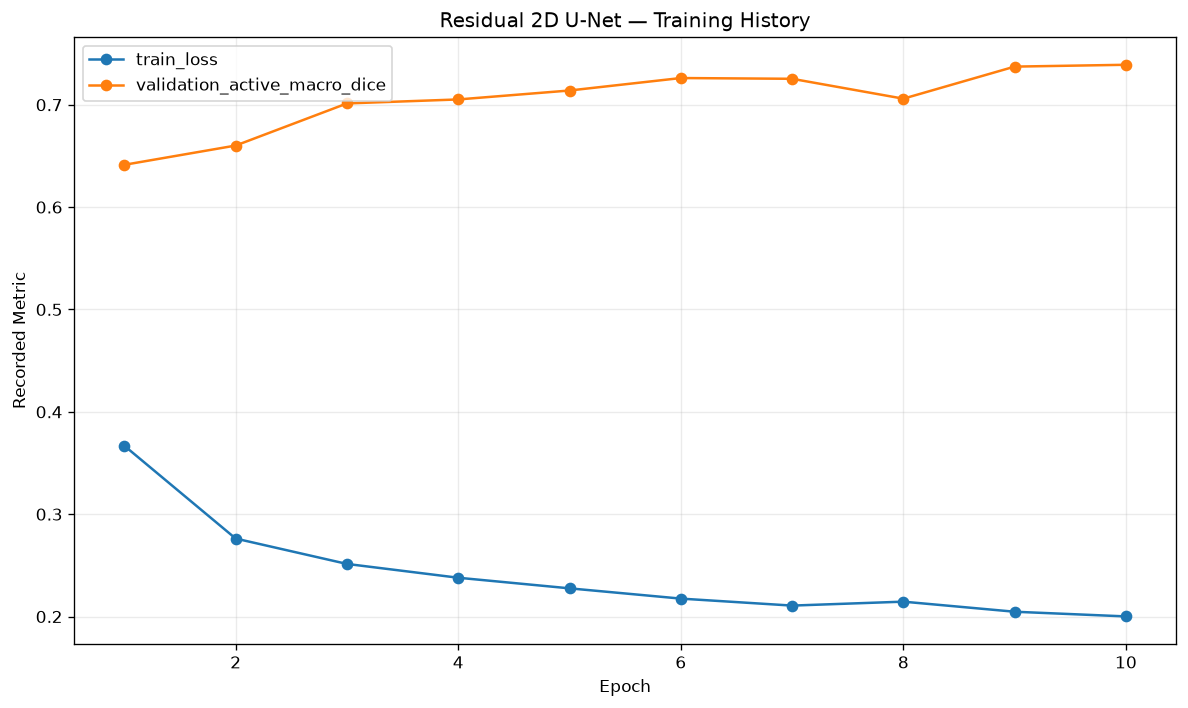

In [5]:
if unet_history is not None:

    epoch_col = find_column(
        unet_history, ["epoch", "epochs"]
    )

    metric_cols = [
        c for c in unet_history.columns
        if any(
            term in str(c).lower()
            for term in ["loss", "dice", "iou"]
        )
        and pd.api.types.is_numeric_dtype(unet_history[c])
    ]

    if epoch_col and metric_cols:

        fig, ax = plt.subplots(figsize=(10, 6))

        for col in metric_cols:
            ax.plot(
                unet_history[epoch_col],
                unet_history[col],
                marker="o",
                label=col
            )

        ax.set_title("Residual 2D U-Net — Training History")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Recorded Metric")
        ax.legend()

        plt.tight_layout()
        plt.savefig(
            OUT / "04_UNet_Training_History.png",
            dpi=250
        )
        plt.show()

    else:
        print(
            "Epoch or loss/metric columns not recognized. "
            "Inspect the history table before plotting."
        )

,method,resolution,macro_dice_mean,macro_dice_std,macro_iou_mean,macro_iou_std,macro_dice_present_gt_mean,macro_dice_present_gt_std,macro_iou_present_gt_mean,macro_iou_present_gt_std,...,ET_hd95_pixels_mean,ET_hd95_pixels_std,ET_tp_mean,ET_tp_std,ET_fp_mean,ET_fp_std,ET_fn_mean,ET_fn_std,ET_tn_mean,ET_tn_std
0,UNet2D,240,0.743423,0.230548,0.66004,0.226139,0.742637,0.223184,0.653937,0.219644,...,9.0956,17.067057,315.675676,347.321005,69.472973,107.807932,57.445946,85.899743,57157.405405,413.430412


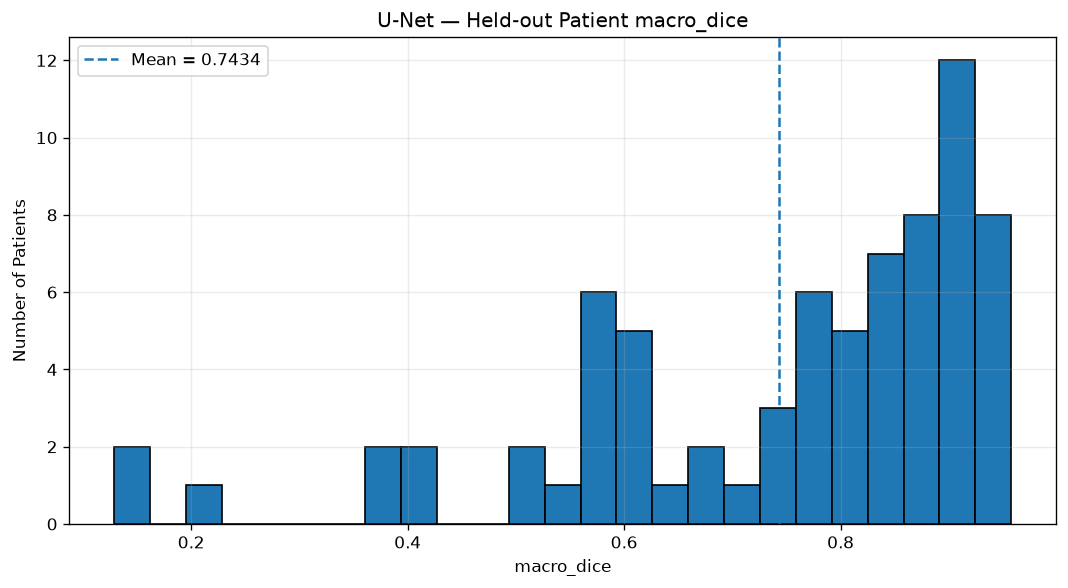

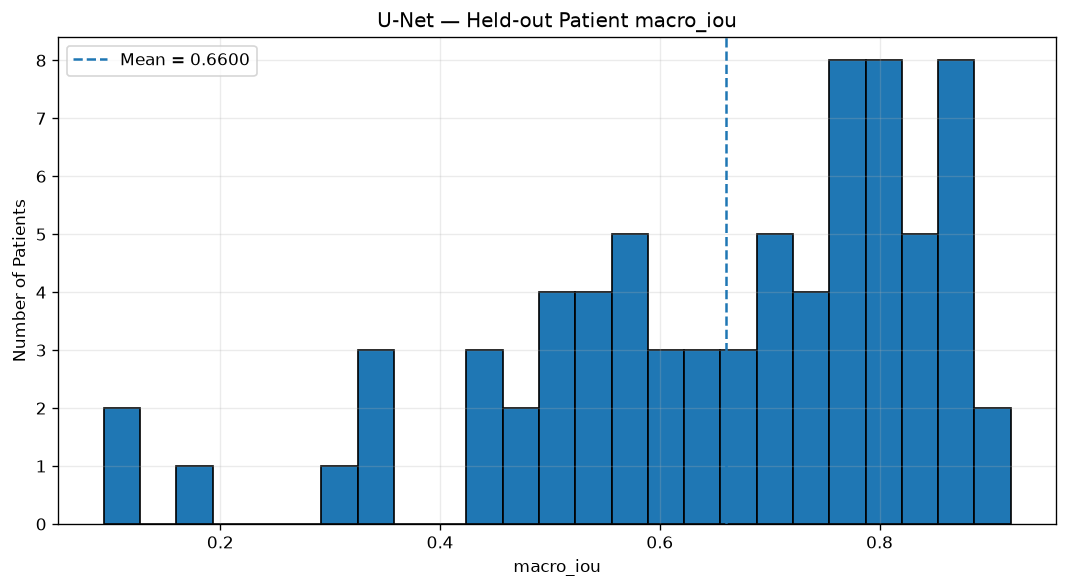

In [6]:
if unet_test is not None:

    display(unet_test)

    unet_test.to_csv(
        OUT / "unet_heldout_test_results.csv",
        index=False
    )

if unet_patient is not None:

    for metric in ["macro_dice", "macro_iou"]:

        col = find_column(
            unet_patient,
            [metric, metric + "_mean"]
        )

        if col is None:
            continue

        values = pd.to_numeric(
            unet_patient[col], errors="coerce"
        ).dropna()

        if values.empty:
            continue

        fig, ax = plt.subplots(figsize=(9, 5))

        ax.hist(values, bins=25, edgecolor="black")
        ax.axvline(
            values.mean(),
            linestyle="--",
            label=f"Mean = {values.mean():.4f}"
        )

        ax.set_title(f"U-Net — Held-out Patient {metric}")
        ax.set_xlabel(metric)
        ax.set_ylabel("Number of Patients")
        ax.legend()

        plt.tight_layout()

        plt.savefig(
            OUT / f"05_UNet_{metric}_Distribution.png",
            dpi=250
        )

        plt.show()

In [7]:
paired_summary = load_csv(
    "msd_unet_vs_rf_paired_test_summary.csv"
)

paired_patient = load_csv(
    "msd_unet_vs_rf_paired_test_per_patient.csv"
)

paired_slice = load_csv(
    "msd_unet_vs_rf_paired_test_per_slice.csv"
)

for name, df in [
    ("Paired summary", paired_summary),
    ("Paired patient results", paired_patient),
    ("Paired slice results", paired_slice)
]:

    print("\n", name)

    if df is not None:
        print("Columns:", list(df.columns))
        display(df.head(10))


 Paired summary
Columns: ['method', 'macro_dice_mean', 'macro_dice_std', 'macro_iou_mean', 'macro_iou_std', 'macro_dice_active_mean', 'macro_dice_active_std', 'macro_iou_active_mean', 'macro_iou_active_std', 'WT_dice_mean', 'WT_dice_std', 'WT_iou_mean', 'WT_iou_std', 'WT_precision_mean', 'WT_precision_std', 'WT_recall_mean', 'WT_recall_std', 'WT_hd95_pixels_mean', 'WT_hd95_pixels_std', 'TC_dice_mean', 'TC_dice_std', 'TC_iou_mean', 'TC_iou_std', 'TC_precision_mean', 'TC_precision_std', 'TC_recall_mean', 'TC_recall_std', 'TC_hd95_pixels_mean', 'TC_hd95_pixels_std', 'ET_dice_mean', 'ET_dice_std', 'ET_iou_mean', 'ET_iou_std', 'ET_precision_mean', 'ET_precision_std', 'ET_recall_mean', 'ET_recall_std', 'ET_hd95_pixels_mean', 'ET_hd95_pixels_std']


,method,macro_dice_mean,macro_dice_std,macro_iou_mean,macro_iou_std,macro_dice_active_mean,macro_dice_active_std,macro_iou_active_mean,macro_iou_active_std,WT_dice_mean,...,ET_dice_mean,ET_dice_std,ET_iou_mean,ET_iou_std,ET_precision_mean,ET_precision_std,ET_recall_mean,ET_recall_std,ET_hd95_pixels_mean,ET_hd95_pixels_std
0,RandomForest,0.427752,0.240270,0.314343,0.211094,0.427752,0.240270,0.314343,0.211094,0.462928,...,0.414109,0.324531,0.316716,0.276718,0.374241,0.327193,0.762201,0.281591,70.591697,30.318355
1,Residual2DUNet,0.743423,0.230548,0.660040,0.226139,0.732803,0.234538,0.645767,0.229133,0.869696,...,0.693023,0.330239,0.609388,0.320451,0.726758,0.305666,0.737728,0.315204,9.095600,17.067057



 Paired patient results
Columns: ['patient_id', 'method', 'macro_dice', 'macro_iou', 'macro_dice_active', 'macro_iou_active', 'WT_dice', 'WT_iou', 'WT_precision', 'WT_recall', 'WT_hd95_pixels', 'TC_dice', 'TC_iou', 'TC_precision', 'TC_recall', 'TC_hd95_pixels', 'ET_dice', 'ET_iou', 'ET_precision', 'ET_recall', 'ET_hd95_pixels']


,patient_id,method,macro_dice,macro_iou,macro_dice_active,macro_iou_active,WT_dice,WT_iou,WT_precision,WT_recall,...,TC_dice,TC_iou,TC_precision,TC_recall,TC_hd95_pixels,ET_dice,ET_iou,ET_precision,ET_recall,ET_hd95_pixels
0,BRATS_002,RandomForest,0.333171,0.214987,0.333171,0.214987,0.277990,0.161452,0.161498,0.998134,...,0.185524,0.103633,0.104422,0.914280,99.747400,0.536001,0.379876,0.403457,0.861609,77.357842
1,BRATS_002,Residual2DUNet,0.784189,0.653971,0.784189,0.653971,0.867093,0.765779,0.779356,0.977092,...,0.715725,0.565545,0.889093,0.637703,3.302699,0.769750,0.630588,0.970076,0.641973,4.181841
2,BRATS_007,RandomForest,0.598413,0.462384,0.598413,0.462384,0.287829,0.168128,0.168167,0.998704,...,0.699992,0.541813,0.582429,0.887484,48.347556,0.807419,0.677210,0.894686,0.735753,4.457220
3,BRATS_007,Residual2DUNet,0.906814,0.831271,0.906814,0.831271,0.907309,0.830364,0.859431,0.961023,...,0.934275,0.877879,0.937060,0.931538,3.929833,0.878859,0.785570,0.840978,0.921649,2.636548
4,BRATS_015,RandomForest,0.711071,0.577426,0.711071,0.577426,0.518058,0.349636,0.349750,0.999026,...,0.699351,0.537948,0.547025,0.970071,95.286633,0.915803,0.844693,0.880424,0.954163,58.725050
5,BRATS_015,Residual2DUNet,0.936262,0.880521,0.936262,0.880521,0.930379,0.869993,0.881580,0.984941,...,0.924074,0.858901,0.925312,0.922865,5.078124,0.954335,0.912667,0.962037,0.946755,2.118034
6,BRATS_016,RandomForest,0.340512,0.238235,0.340512,0.238235,0.360975,0.220647,0.220721,0.998746,...,0.313887,0.228743,0.234363,0.475094,98.333993,0.346675,0.265316,0.315230,0.385089,79.240878
7,BRATS_016,Residual2DUNet,0.588736,0.531652,0.588736,0.531652,0.906187,0.829518,0.854740,0.965344,...,0.475038,0.452451,0.483581,0.466792,16.129016,0.384984,0.312987,0.462572,0.329685,15.755593
8,BRATS_017,RandomForest,0.428350,0.284925,0.428350,0.284925,0.341939,0.206583,0.206675,0.998235,...,0.363792,0.229689,0.249455,0.738893,91.859766,0.579318,0.418502,0.606893,0.555369,87.977255
9,BRATS_017,Residual2DUNet,0.872788,0.778099,0.872788,0.778099,0.877505,0.783473,0.874093,0.885795,...,0.890110,0.809267,0.969096,0.838409,3.025757,0.850748,0.741557,0.968447,0.763286,4.865220



 Paired slice results
Columns: ['patient_id', 'slice_index', 'sample_id', 'method', 'resolution', 'macro_dice', 'macro_iou', 'macro_dice_active', 'macro_iou_active', 'WT_dice', 'WT_iou', 'WT_precision', 'WT_recall', 'WT_hd95_pixels', 'TC_dice', 'TC_iou', 'TC_precision', 'TC_recall', 'TC_hd95_pixels', 'ET_dice', 'ET_iou', 'ET_precision', 'ET_recall', 'ET_hd95_pixels']


,patient_id,slice_index,sample_id,method,resolution,macro_dice,macro_iou,macro_dice_active,macro_iou_active,WT_dice,...,TC_dice,TC_iou,TC_precision,TC_recall,TC_hd95_pixels,ET_dice,ET_iou,ET_precision,ET_recall,ET_hd95_pixels
0,BRATS_224,50,BRATS_224_z050,RandomForest,240,0.064677,0.035243,0.064677,0.035243,0.177798,...,0.011390,0.005727,0.005760,0.500000,74.818890,0.004843,0.002427,0.002427,1.000000,83.784160
1,BRATS_224,50,BRATS_224_z050,Residual2DUNet,240,0.249495,0.199355,0.249495,0.199355,0.748486,...,0.000000,0.000000,NaN,0.000000,NaN,0.000000,0.000000,NaN,0.000000,NaN
2,BRATS_224,55,BRATS_224_z055,RandomForest,240,0.166704,0.091070,0.166704,0.091070,0.167475,...,0.141019,0.075858,0.081161,0.537255,79.602763,0.191617,0.105960,0.106785,0.932039,87.138955
3,BRATS_224,55,BRATS_224_z055,Residual2DUNet,240,0.586908,0.458920,0.586908,0.458920,0.883091,...,0.288591,0.168627,1.000000,0.168627,13.992321,0.589041,0.417476,1.000000,0.417476,11.843499
4,BRATS_002,104,BRATS_002_z104,RandomForest,240,0.265328,0.157587,0.265328,0.157587,0.284941,...,0.121212,0.064516,0.065123,0.873786,99.969989,0.389831,0.242105,0.254613,0.831325,76.993268
5,BRATS_002,104,BRATS_002_z104,Residual2DUNet,240,0.736380,0.595251,0.736380,0.595251,0.884335,...,0.622517,0.451923,0.979167,0.456311,4.605398,0.702290,0.541176,0.958333,0.554217,4.824621
6,BRATS_002,112,BRATS_002_z112,RandomForest,240,0.401015,0.272387,0.401015,0.272387,0.271038,...,0.249836,0.142750,0.143722,0.954774,99.524810,0.682171,0.517647,0.552301,0.891892,77.722416
7,BRATS_002,112,BRATS_002_z112,Residual2DUNet,240,0.831998,0.712691,0.831998,0.712691,0.849851,...,0.808933,0.679167,0.799020,0.819095,2.000000,0.837209,0.720000,0.981818,0.729730,3.539060
8,BRATS_043,98,BRATS_043_z098,RandomForest,240,0.377636,0.243463,0.377636,0.243463,0.184991,...,0.393517,0.244956,0.245253,0.995082,68.414180,0.554401,0.383509,0.384986,0.990099,69.046935
9,BRATS_043,98,BRATS_043_z098,Residual2DUNet,240,0.930216,0.870199,0.930216,0.870199,0.902818,...,0.950989,0.906557,1.000000,0.906557,1.414214,0.936842,0.881188,1.000000,0.881188,1.000000


method,RandomForest,Residual2DUNet
Metric,,
ET_dice_mean,0.414109,0.693023
TC_dice_mean,0.406219,0.667548
WT_dice_mean,0.462928,0.869696
macro_dice_active_mean,0.427752,0.732803
macro_dice_mean,0.427752,0.743423
macro_iou_active_mean,0.314343,0.645767
macro_iou_mean,0.314343,0.660040


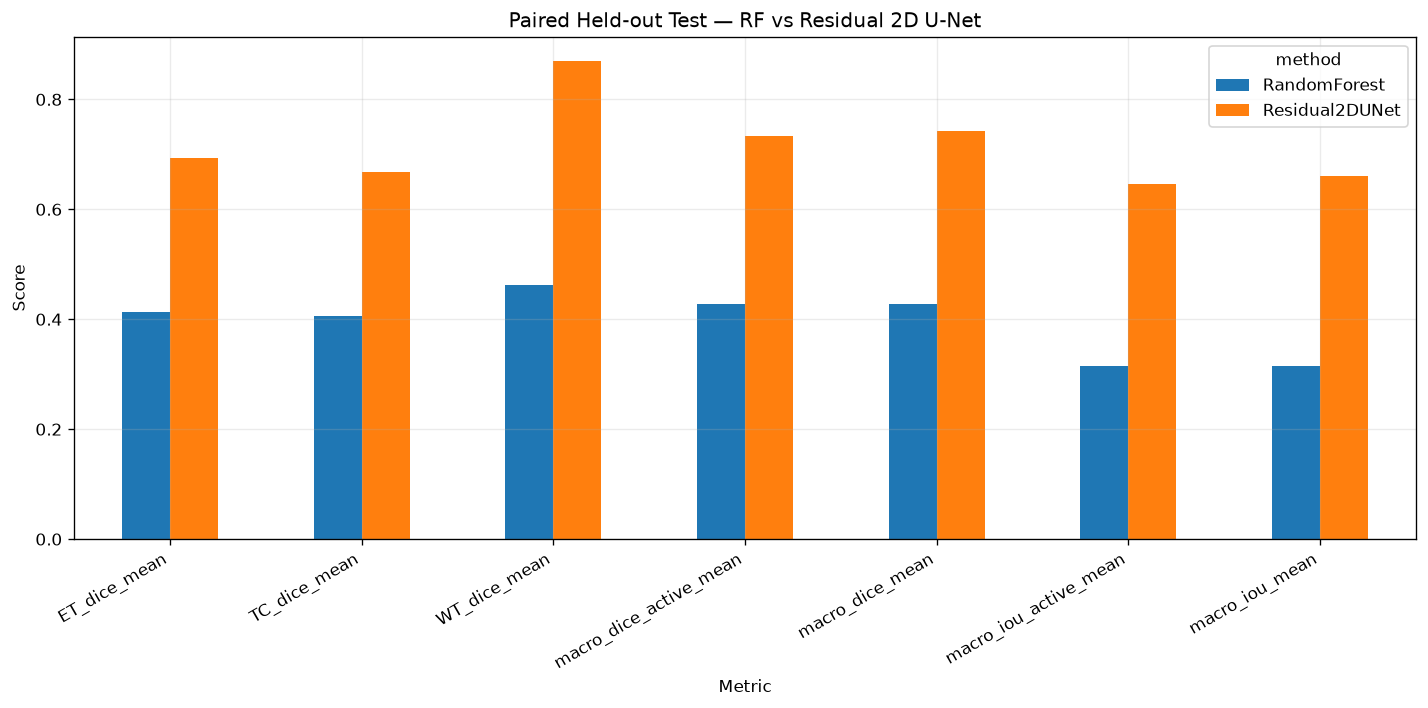

In [8]:
if paired_summary is not None:

    method_col = find_column(
        paired_summary,
        ["method", "model", "model_name"]
    )

    metrics = [
        c for c in paired_summary.columns
        if any(
            x in c.lower()
            for x in [
                "macro_dice_mean",
                "macro_iou_mean",
                "macro_dice_active_mean",
                "macro_iou_active_mean",
                "wt_dice_mean",
                "tc_dice_mean",
                "et_dice_mean"
            ]
        )
    ]

    if method_col and metrics:

        comparison = paired_summary.melt(
            id_vars=[method_col],
            value_vars=metrics,
            var_name="Metric",
            value_name="Score"
        )

        comparison["Score"] = pd.to_numeric(
            comparison["Score"], errors="coerce"
        )

        pivot = comparison.pivot_table(
            index="Metric",
            columns=method_col,
            values="Score",
            aggfunc="mean"
        )

        display(pivot)

        ax = pivot.plot(
            kind="bar",
            figsize=(12, 6)
        )

        ax.set_title(
            "Paired Held-out Test — RF vs Residual 2D U-Net"
        )
        ax.set_ylabel("Score")
        ax.set_ylim(bottom=0)

        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()

        plt.savefig(
            OUT / "06_RF_vs_UNet_Paired_Comparison.png",
            dpi=250,
            bbox_inches="tight"
        )

        plt.show()

    else:
        print("Paired summary schema needs inspection.")

In [9]:
quantum_json_files = sorted(
    QUANTUM.rglob("*.json")
)

quantum_objects = {}

def preview_json(obj, depth=0, max_depth=4):

    indent = "  " * depth

    if isinstance(obj, dict):

        for key, value in obj.items():

            if isinstance(value, dict):
                print(f"{indent}{key}: dict ({len(value)} keys)")

                if depth < max_depth:
                    preview_json(value, depth + 1, max_depth)

            elif isinstance(value, list):
                print(f"{indent}{key}: list ({len(value)} entries)")

                if value and depth < max_depth:
                    preview_json(value[0], depth + 1, max_depth)

            else:
                print(f"{indent}{key}: {value}")

    elif isinstance(obj, list):

        for value in obj[:8]:
            preview_json(value, depth + 1, max_depth)


for path in quantum_json_files:

    try:

        obj = json.loads(
            path.read_text(encoding="utf-8-sig")
        )

        key = path.relative_to(ROOT).as_posix()

        quantum_objects[key] = obj

        print("\n" + "=" * 80)
        print(key)
        print("=" * 80)

        preview_json(obj)

    except Exception as exc:

        print("ERROR:", path.name, exc)


print("\nTotal quantum JSON files:", len(quantum_objects))


outputs/reports/quantum/frqi_16_resource_profile.json
representation: FRQI
n_qubits: 9
statevector_dimension: 512
nonzero_amplitudes: 348
logical_depth: 1
logical_ops: dict (1 keys)
  initialize: 1
transpilation_performed: True
cost_model_note: Initialize is a high-level exact state-preparation instruction; it is not free QRAM. Transpiled gate counts are reported only when transpilation completes.
transpiled_depth: 1
transpiled_ops: dict (1 keys)
  initialize: 1

outputs/reports/quantum/frqi_32_resource_profile.json
representation: FRQI
n_qubits: 11
statevector_dimension: 2048
nonzero_amplitudes: 1347
logical_depth: 1
logical_ops: dict (1 keys)
  initialize: 1
transpilation_performed: True
cost_model_note: Initialize is a high-level exact state-preparation instruction; it is not free QRAM. Transpiled gate counts are reported only when transpilation completes.
transpiled_depth: 1
transpiled_ops: dict (1 keys)
  initialize: 1

outputs/reports/quantum/highres/BRATS_224_z53_128_frqi_state

In [10]:
quantum_values = []

def walk_json(obj, keys, source):

    if isinstance(obj, dict):

        for k, v in obj.items():
            walk_json(v, keys + [str(k)], source)

    elif isinstance(obj, list):

        if obj and all(
            isinstance(v, (int, float)) and not isinstance(v, bool)
            for v in obj
        ):

            arr = np.asarray(obj, dtype=float)

            quantum_values.append({
                "Source": source,
                "JSON_Key": ".".join(keys),
                "Value": np.nan,
                "Array_Count": len(arr),
                "Array_Mean": arr.mean(),
                "Array_Std": arr.std(ddof=1) if len(arr) > 1 else 0,
                "Array_Min": arr.min(),
                "Array_Max": arr.max()
            })

        else:

            for i, v in enumerate(obj):
                walk_json(v, keys + [f"[{i}]"], source)

    elif isinstance(obj, (int, float)) and not isinstance(obj, bool):

        quantum_values.append({
            "Source": source,
            "JSON_Key": ".".join(keys),
            "Value": float(obj),
            "Array_Count": 1,
            "Array_Mean": float(obj),
            "Array_Std": 0,
            "Array_Min": float(obj),
            "Array_Max": float(obj)
        })


for source, obj in quantum_objects.items():
    walk_json(obj, [], source)


quantum_numeric = pd.DataFrame(quantum_values)

display(quantum_numeric.head(250))

quantum_numeric.to_csv(
    OUT / "quantum_numeric_inventory.csv",
    index=False
)

,Source,JSON_Key,Value,Array_Count,Array_Mean,Array_Std,Array_Min,Array_Max
0,outputs/reports/quantum/frqi_16_resource_profi...,n_qubits,9.0,1,9.0,0.0,9.0,9.0
1,outputs/reports/quantum/frqi_16_resource_profi...,statevector_dimension,512.0,1,512.0,0.0,512.0,512.0
2,outputs/reports/quantum/frqi_16_resource_profi...,nonzero_amplitudes,348.0,1,348.0,0.0,348.0,348.0
3,outputs/reports/quantum/frqi_16_resource_profi...,logical_depth,1.0,1,1.0,0.0,1.0,1.0
4,outputs/reports/quantum/frqi_16_resource_profi...,logical_ops.initialize,1.0,1,1.0,0.0,1.0,1.0
...,...,...,...,...,...,...,...,...
245,outputs/reports/quantum/highres/BRATS_224_z53_...,patch_records.[10].row,2.0,1,2.0,0.0,2.0,2.0
246,outputs/reports/quantum/highres/BRATS_224_z53_...,patch_records.[10].column,2.0,1,2.0,0.0,2.0,2.0
247,outputs/reports/quantum/highres/BRATS_224_z53_...,patch_records.[10].origin_y,64.0,1,64.0,0.0,64.0,64.0
248,outputs/reports/quantum/highres/BRATS_224_z53_...,patch_records.[10].origin_x,64.0,1,64.0,0.0,64.0,64.0


In [11]:
QUANTUM_METRIC_MAP = {
    "MSE": ["mse", "mean_squared_error"],
    "PSNR": ["psnr", "psnr_db"],
    "SSIM": ["ssim"],
    "Runtime": ["runtime_seconds", "execution_time_seconds"],
    "Qubits": ["qubits", "num_qubits"],
    "Circuit Depth": ["circuit_depth", "depth"],
    "Total Gates": ["total_gates", "gate_count"],
    "Transpiled Gates": ["transpiled_gates"],
    "Shots": ["shots", "shot_count"],
    "Tiles": ["tile_count", "num_tiles"]
}

mapped_quantum = []

for _, row in quantum_numeric.iterrows():

    key = row["JSON_Key"].lower()

    for metric, aliases in QUANTUM_METRIC_MAP.items():

        if any(
            alias in key for alias in aliases
        ):

            mapped_quantum.append({
                "Metric": metric,
                "Value": (
                    row["Value"]
                    if pd.notna(row["Value"])
                    else row["Array_Mean"]
                ),
                "Source": row["Source"],
                "JSON_Key": row["JSON_Key"]
            })

mapped_quantum = pd.DataFrame(mapped_quantum)

display(mapped_quantum)

mapped_quantum.to_csv(
    OUT / "quantum_mapped_metrics.csv",
    index=False
)

,Metric,Value,Source,JSON_Key
0,Qubits,9.0,outputs/reports/quantum/frqi_16_resource_profi...,n_qubits
1,Circuit Depth,1.0,outputs/reports/quantum/frqi_16_resource_profi...,logical_depth
2,Circuit Depth,1.0,outputs/reports/quantum/frqi_16_resource_profi...,transpiled_depth
3,Qubits,11.0,outputs/reports/quantum/frqi_32_resource_profi...,n_qubits
4,Circuit Depth,1.0,outputs/reports/quantum/frqi_32_resource_profi...,logical_depth
...,...,...,...,...
774,Qubits,16.0,outputs/reports/quantum/neqr_16_resource_profi...,n_qubits
775,Circuit Depth,1.0,outputs/reports/quantum/neqr_16_resource_profi...,logical_depth
776,Circuit Depth,1.0,outputs/reports/quantum/neqr_16_resource_profi...,transpiled_depth
777,Qubits,18.0,outputs/reports/quantum/neqr_32_resource_profi...,n_qubits


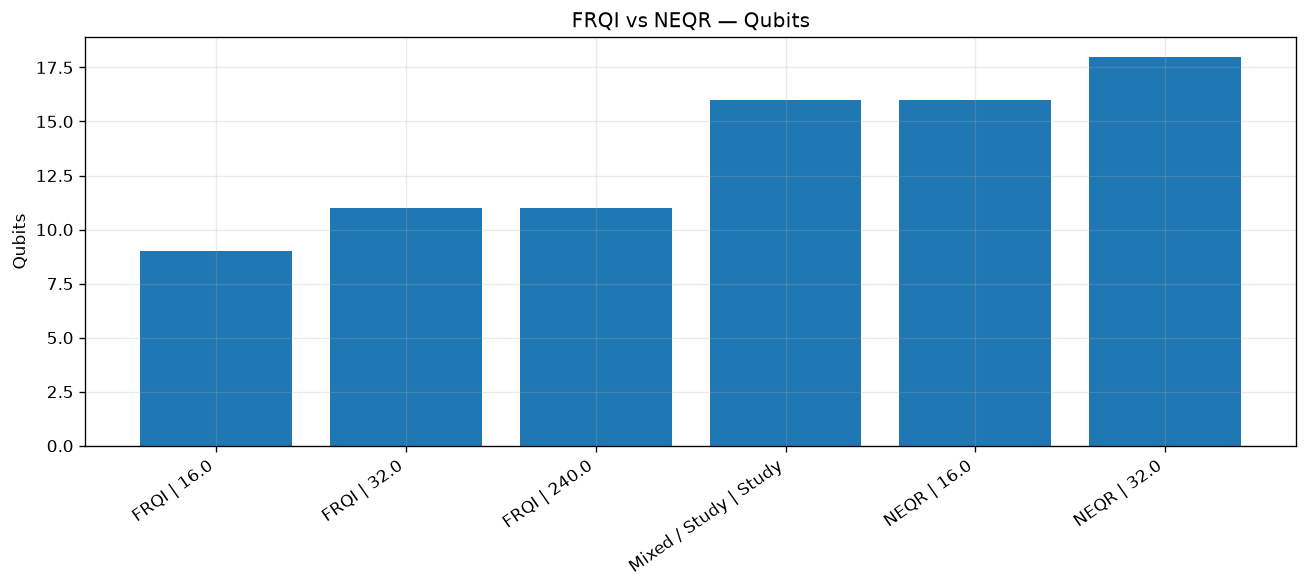

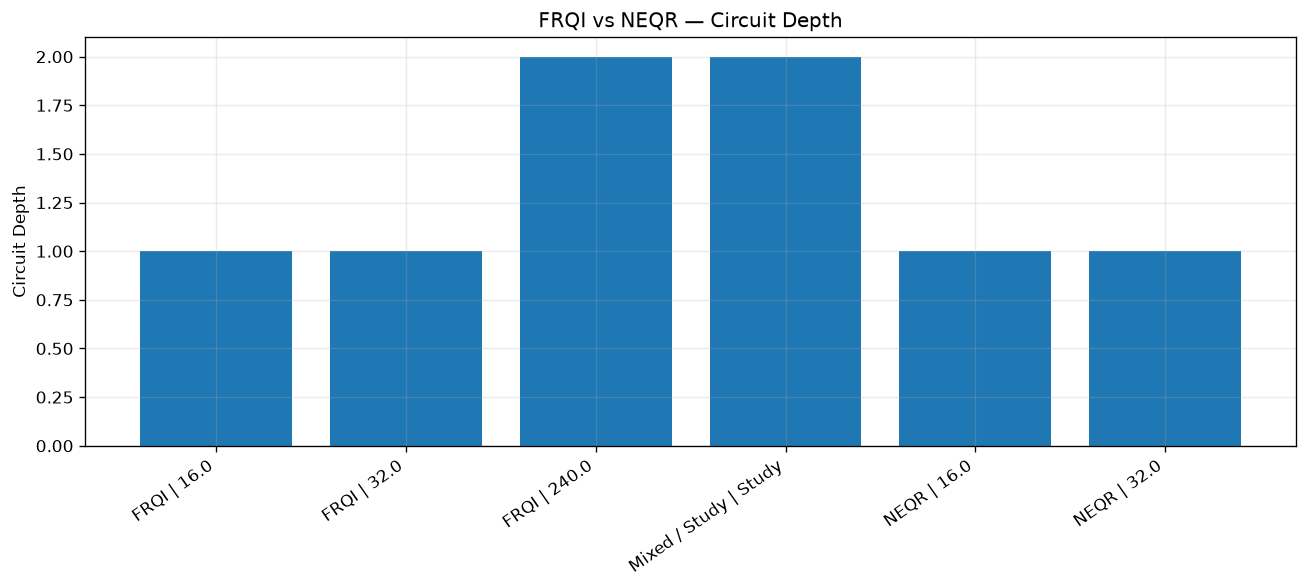

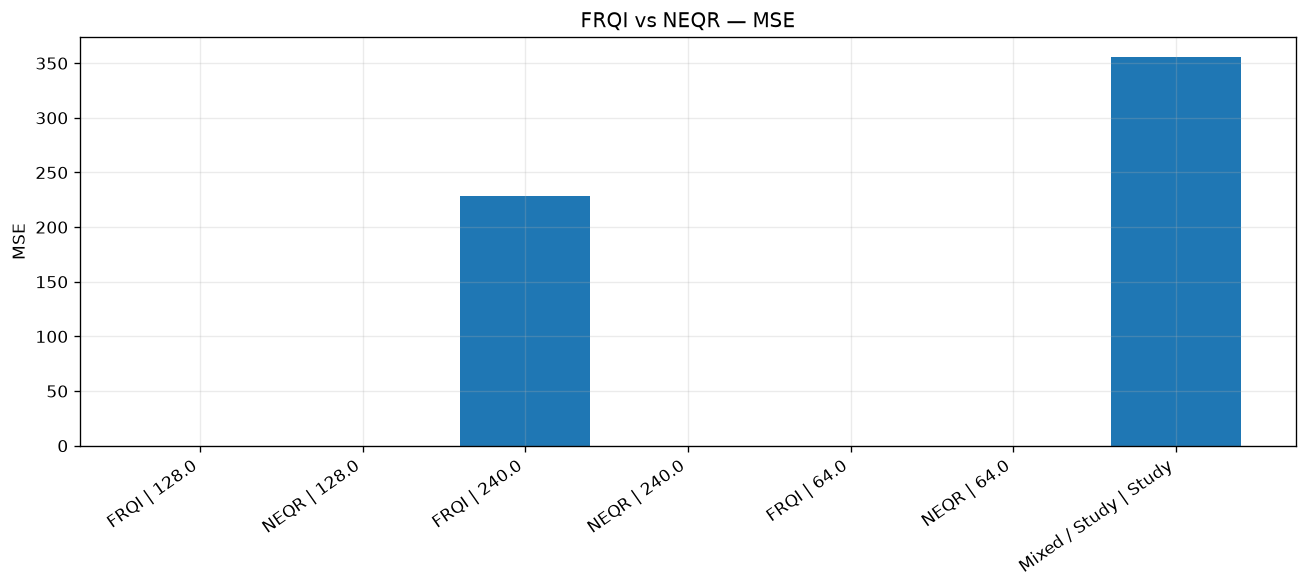

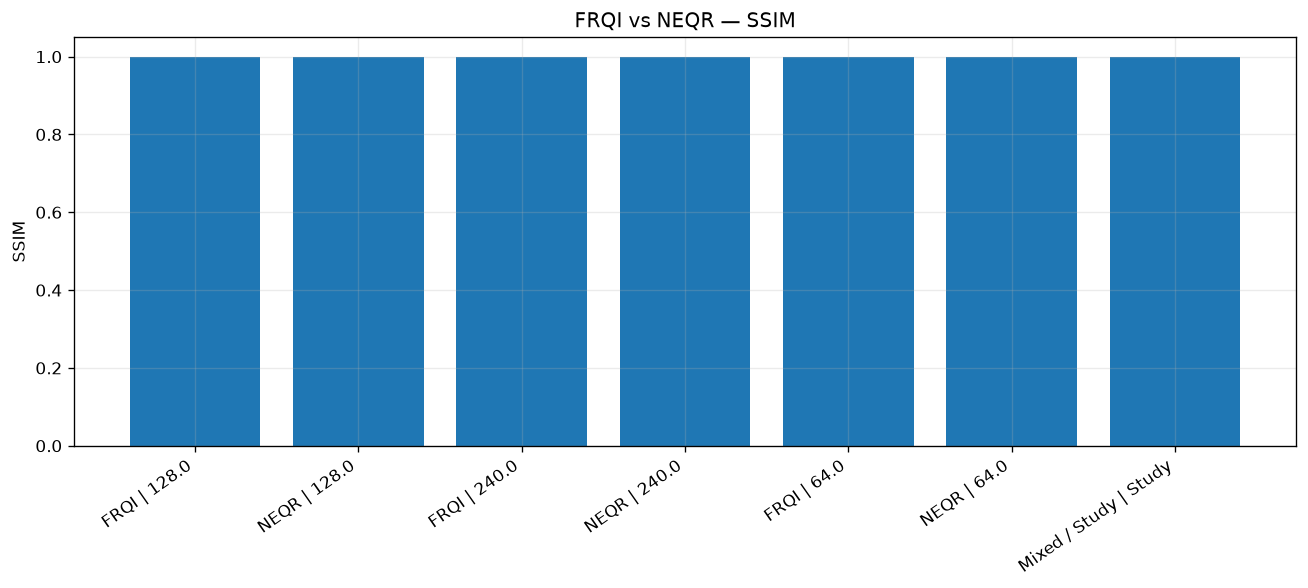

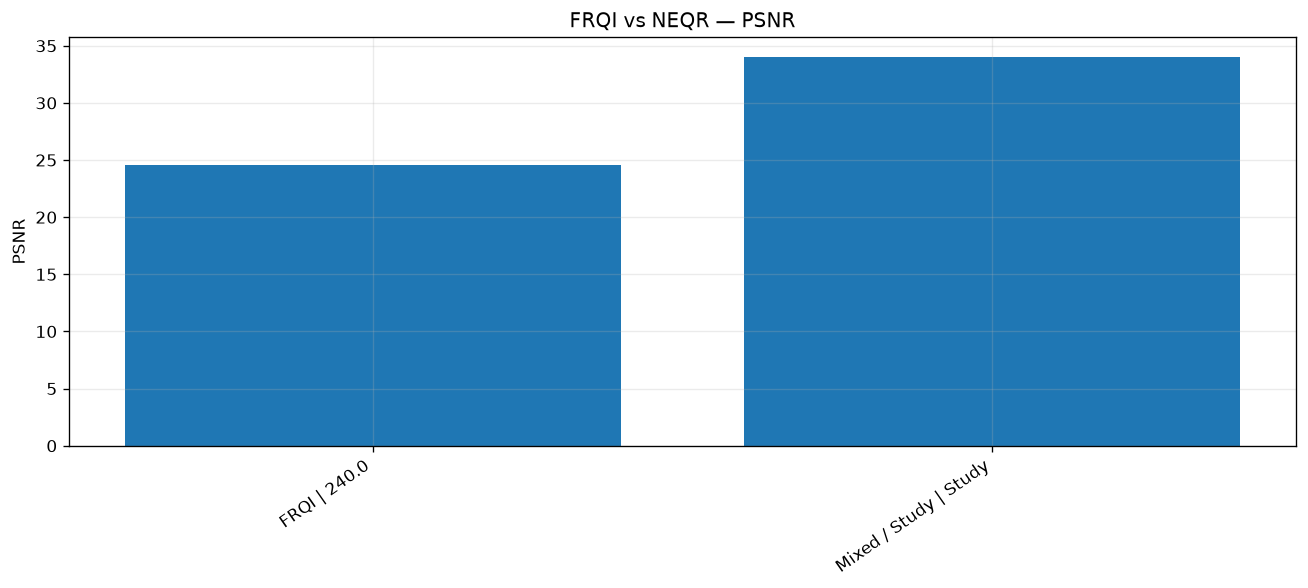

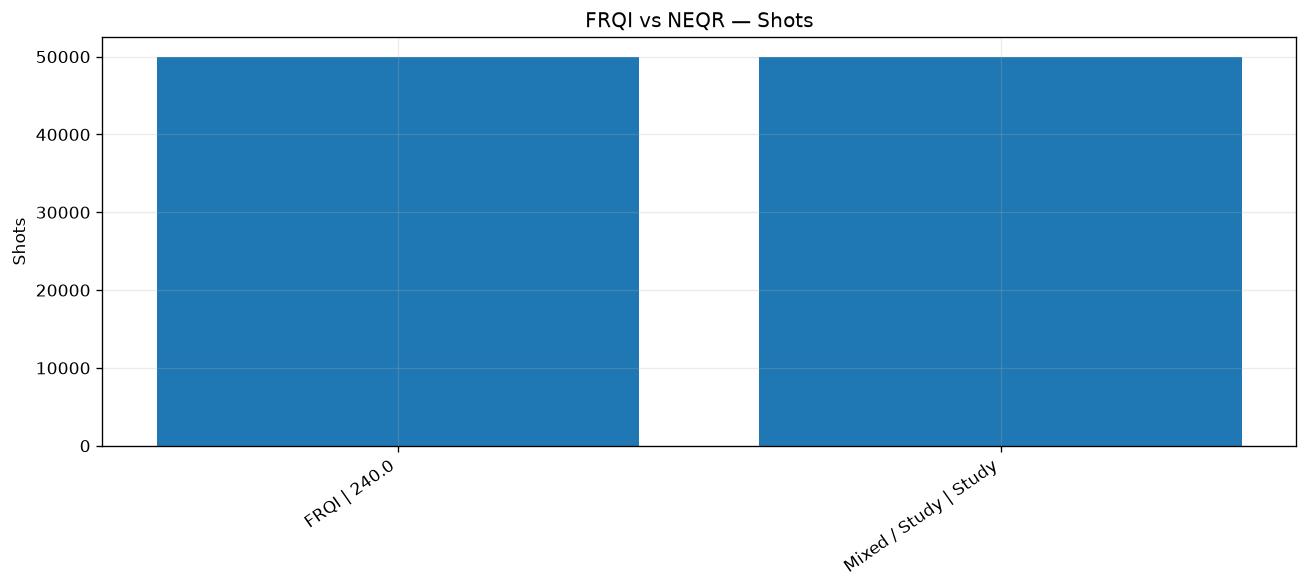

In [12]:
def quantum_encoding(source):

    name = source.lower()

    if "frqi" in name:
        return "FRQI"

    if "neqr" in name:
        return "NEQR"

    return "Mixed / Study"


def quantum_resolution(source):

    match = re.search(
        r"(16|32|64|128|240)(?:_|x)",
        source.lower()
    )

    return int(match.group(1)) if match else np.nan


if not mapped_quantum.empty:

    mapped_quantum["Encoding"] = (
        mapped_quantum["Source"].apply(quantum_encoding)
    )

    mapped_quantum["Resolution"] = (
        mapped_quantum["Source"].apply(quantum_resolution)
    )

    for metric in mapped_quantum["Metric"].unique():

        data = mapped_quantum[
            mapped_quantum["Metric"] == metric
        ].copy()

        fig, ax = plt.subplots(figsize=(11, 5))

        labels = [
            f"{row.Encoding} | {row.Resolution if pd.notna(row.Resolution) else 'Study'}"
            for row in data.itertuples()
        ]

        ax.bar(labels, data["Value"])

        ax.set_title(f"FRQI vs NEQR — {metric}")
        ax.set_ylabel(metric)

        plt.xticks(rotation=35, ha="right")
        plt.tight_layout()

        filename = (
            "Quantum_" + re.sub(r"\W+", "_", metric) + ".png"
        )

        plt.savefig(
            OUT / filename,
            dpi=250,
            bbox_inches="tight"
        )

        plt.show()

else:
    print(
        "No metrics mapped. Review the JSON key inventory "
        "and update QUANTUM_METRIC_MAP."
    )

In [13]:
hybrid_candidates = []

for _, row in quantum_numeric.iterrows():

    key = row["JSON_Key"].lower()

    if any(
        term in key
        for term in [
            "segmentation",
            "dice",
            "iou",
            "tumour",
            "tumor",
            "wt_",
            "tc_",
            "et_"
        ]
    ):

        hybrid_candidates.append({
            "Source": row["Source"],
            "JSON_Key": row["JSON_Key"],
            "Value": (
                row["Value"]
                if pd.notna(row["Value"])
                else row["Array_Mean"]
            )
        })


hybrid_evidence = pd.DataFrame(hybrid_candidates)

display(hybrid_evidence)

hybrid_evidence.to_csv(
    OUT / "hybrid_experiment_metric_candidates.csv",
    index=False
)

,Source,JSON_Key,Value
0,outputs/reports/quantum/highres/BRATS_224_z53_...,model_metadata.probability_calibration.tumour_...,0.975000
1,outputs/reports/quantum/highres/BRATS_224_z53_...,model_metadata.probability_calibration.validat...,0.521078
2,outputs/reports/quantum/highres/BRATS_224_z53_...,model_metadata.probability_calibration.raw_arg...,0.364327
3,outputs/reports/quantum/highres/BRATS_224_z53_...,model_metadata.probability_calibration.candida...,0.233770
4,outputs/reports/quantum/highres/BRATS_224_z53_...,model_metadata.probability_calibration.candida...,0.220156
...,...,...,...
1328,outputs/reports/quantum/msd_quantum_study.json,results.[24].segmentation.n_regions_present_gt,3.000000
1329,outputs/reports/quantum/msd_quantum_study.json,results.[24].segmentation.n_regions_empty_gt,0.000000
1330,outputs/reports/quantum/msd_quantum_study.json,results.[24].segmentation.n_regions_empty_pred...,0.000000
1331,outputs/reports/quantum/msd_quantum_study.json,results.[24].segmentation.n_regions_both_empty,0.000000


In [14]:
print("PROJECT QUANTUM V3.4 — FINAL ANALYSIS OUTPUTS")

for path in sorted(OUT.glob("*")):

    if path.is_file():

        print(
            f"{path.name:55} "
            f"{path.stat().st_size / 1024:.2f} KB"
        )

PROJECT QUANTUM V3.4 — FINAL ANALYSIS OUTPUTS
01_RF_Macro_Dice.png                                    49.78 KB
02_RF_Macro_IoU.png                                     47.15 KB
03_RF_Active_Dice.png                                   51.14 KB
04_UNet_Training_History.png                            99.67 KB
05_UNet_macro_dice_Distribution.png                     58.10 KB
05_UNet_macro_iou_Distribution.png                      57.14 KB
06_RF_vs_UNet_Paired_Comparison.png                     125.48 KB
hybrid_experiment_metric_candidates.csv                 161.95 KB
Quantum_Circuit_Depth.png                               88.19 KB
quantum_mapped_metrics.csv                              90.10 KB
Quantum_MSE.png                                         88.72 KB
quantum_numeric_inventory.csv                           793.08 KB
Quantum_PSNR.png                                        56.44 KB
Quantum_Qubits.png                                      80.79 KB
Quantum_Shots.png                        